# (final) EHR application analysis

One notebook for **every result of the redrafted paper**. It replaces notebooks 2–6 for the paper.

* **Tokenizer:** hop-dependent decay, so every hop multiplies the score by $\lambda$ (Eq. 1). The status-dependent variant stays in `decay_with_prim_fd/`.
* **Concept set $M$:** only the SNOMED CT concepts that occur in the HERO data *and* are in the candidate subgraph. The 46k mapped-concept benchmark is no longer used.
* **Metrics:** the core metrics are the **branch-weighted PC** (`br_weighted_PC`), unique rate, unknown rate and tokens per concept. `br_weighted_PC` uses the same expansion as the context trees, but every concept splits its weight equally between its outgoing relationships, so many tokens in one branch cannot hide a branch without a token. The former PC (semantic fidelity = completeness × proximity) is still computed and saved for versioning, but not used in the analysis. `num_effective_token` (selected tokens that at least one concept uses) is reported for information. See `src/graph_tokenizer_gd_tree_dev/fidelity_eval.py`.

| Notebook part | Paper section |
|---|---|
| 1 Data, 2 Candidate subgraph | 4.1 Experimental setup |
| 3 Our selection, 4 Baselines, 5 Evaluation | 3.7 / 4.1 (19 configurations) |
| 6 Example context trees | 4.2 (illustrative paragraph) |
| 7 Ranking, 8 Effect of $k$, 9 Effect of $\lambda$ | 4.2 Selection methods compared |
| 8b Effective tokens | informational |
| 10 Distribution of the branch-weighted PC | 3.6 metric definition, 5.3 discussion |
| 11 Patient data vs truncation | 4.3 |
| 12 Metric correlations | 5.3 discussion |
| 13 Key numbers | numbers to quote in the text |

**Run order.** Run top to bottom from the repository root. Every output goes to one folder, `CFG.out_dir`, with these subfolders:
* `figures/`, `tables/`, `results/`, `ehr/`
* caches: `subgraph/`, `ours/`, `baselines/`

Expensive steps are cached (evaluation: one file per method). They are recomputed only if the file is missing, lacks the new metrics, or `CFG.recompute = True`.

In [1]:
%load_ext autoreload
%autoreload all

In [2]:
import glob
import json
import multiprocessing as mp
import os
import pickle
import re
from collections import Counter, defaultdict
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import polars as pl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MultipleLocator
from tqdm.auto import tqdm

import src.graph_tokenizer_gd_tree_dev.config as config
import src.graph_tokenizer_gd_tree_dev.graph_fct as graph_fct
import src.graph_tokenizer_gd_tree_dev.tokenizer as tokenizer
import src.graph_tokenizer_gd_tree_dev.classical_selectors as classical_selectors
import src.graph_tokenizer_gd_tree_dev.utils as utils
import src.graph_tokenizer_gd_tree_dev.fidelity_eval as fe
import src.graph_tokenizer_gd_tree_dev.fast_greedy as fg
import src.graph_tokenizer_gd_tree_dev.ehr_tokenization as et
import src.graph_tokenizer_gd_tree_dev.ehr_paper_tables as ept
import src.graph_tokenizer_gd_tree_dev.ehr_plots as ep
from src.graph_tokenizer_gd_tree_dev.eval import build_context_trees, _iter_contexts, distance_score
from src.graph_tokenizer_gd_tree_dev.eval import br_weighted_pc_per_concept, br_weighted_pc_concept
from src.graph_tokenizer_gd_tree_dev.tokenizer import signature
from src.graph_tokenizer_gd_tree_dev.drilldown import render_context_tree

## 0. Configuration

All choices of the paper live in this one cell. **Hop-dependent decay** is the only mode in this notebook.

In [3]:
@dataclass(frozen=True)
class FinalConfig:
    # --- tokenizer (hop-dependent decay: each hop multiplies by lambda) ---------------------
    decay: str = "hop"
    D: int = config.TokenizerParam.max_dist_candidate          # search horizon (9)
    lam_main: float = 0.9                                       # configuration used in the paper
    k_main: int = 5000                                          # budget used in the examples and Sec. 4.3
    lambdas: tuple = tuple(float(x) for x in np.round(np.arange(0.0, 1.01, 0.1), 1))
    lambdas_fine: tuple = tuple(float(x) for x in np.round(np.arange(0.91, 1.0, 0.01), 2))
    run_fine_lambdas: bool = False                              # True adds 0.91-0.99 (lambda figure only)

    # --- benchmark budgets: 27 values -> 3 compression levels of 9 budgets each -------------
    ks_bench: tuple = tuple(range(250, 6751, 250))
    n_random_iters: int = 20

    # --- patient data (Sec. 4.3) ------------------------------------------------------------
    ks_ehr: tuple = (250, 500, 1000, 2000, 3500, 5000, 7500, 10000)   # + |M| appended below
    ehr_extra_baselines: tuple = ("personalized_pagerank",)           # optional: () to skip
    rare_token_events: int = 10                                       # "rarest token >= 10 events"
    data_max_year: int = 2025                                         # events up to this year

    # --- paths: every output (caches, results, tables, figures) goes under out_dir --------------
    out_dir: str = "D:/greedy_graph_data/final_hero/"
    recompute: bool = False
    n_jobs: int = -1                                                  # -1 = all cores


CFG = FinalConfig()
assert CFG.decay == "hop", "this notebook implements the hop-dependent decay only"
D = CFG.D
N_WORKERS = os.cpu_count() if CFG.n_jobs == -1 else CFG.n_jobs

DIRS = {name: os.path.join(CFG.out_dir, name) + "/" for name in
        ["subgraph", "ours", "baselines", "results", "tables", "ehr", "figures"]}
for p in DIRS.values():
    os.makedirs(p, exist_ok=True)


def lam_name(lam):
    """File name / method id of one lambda run: 0.9 -> '0.9', 1 -> '1.0', 0.91 -> '0.91'."""
    return str(float(round(lam, 2)))


LAM_MAIN = lam_name(CFG.lam_main)
LAMBDA_IDS = [lam_name(l) for l in CFG.lambdas]
LAMBDA_FINE_IDS = [lam_name(l) for l in CFG.lambdas_fine] if CFG.run_fine_lambdas else []

# the 19 compared configurations (Sec. 3.7): 11 lambdas, set-cover ablation, 7 baselines
BASELINES = ["highest_degree", "highest_degree_dist_1", "most_children", "pagerank",
             "personalized_pagerank", "closeness_centrality", "k_random_all_samples"]
ABLATION = "discrete_set_cover"
RANKED_METHODS = LAMBDA_IDS + [ABLATION] + BASELINES

FAMILY = {**{l: "ours" for l in LAMBDA_IDS + LAMBDA_FINE_IDS},
          ABLATION: "ours(ablation)",
          "highest_degree": "degree-based", "highest_degree_dist_1": "degree-based",
          "most_children": "degree-based",
          "pagerank": "centrality-based", "personalized_pagerank": "centrality-based",
          "closeness_centrality": "centrality-based",
          "k_random_all_samples": "random"}
DISPLAY = {**{l: f"Ours ($\\lambda$ = {l})" for l in LAMBDA_IDS + LAMBDA_FINE_IDS},
           ABLATION: "Set cover (ablation)",
           "highest_degree": "Highest degree ($d \\leq D$)",
           "highest_degree_dist_1": "Highest degree ($d \\leq 1$)",
           "most_children": "Most IS\\_A children",
           "pagerank": "PageRank",
           "personalized_pagerank": "Personalized PageRank",
           "closeness_centrality": "Closeness centrality",
           "k_random_all_samples": "Random"}

# metric names as printed in figures and tables -- rename the PC metric here only
FIDELITY_NAME = "Branch-weighted PC"
METRIC_TITLE = {
    "br_weighted_PC": f"{FIDELITY_NAME} ($\\uparrow$)",
    "br_completeness": "Branch-weighted completeness ($\\uparrow$)",
    "br_proximity": "Branch-weighted proximity ($\\uparrow$)",
    "effective_token_share": "Effective tokens / $k$ ($\\uparrow$)",
    "semantic_fidelity": "PC, legacy ($\\uparrow$)",
    "unique_rate": "Unique rate ($\\uparrow$)",
    "unknown_rate": "Unknown rate ($\\downarrow$)",
    "tokens_per_concept": "Tokens per concept ($\\downarrow$)",
    "uncovered_branch_rate": "Uncovered branch rate ($\\downarrow$)",
    "completeness": "Completeness ($\\uparrow$)",
    "proximity": "Proximity ($\\uparrow$)",
}
CORE = fe.CORE_METRICS            # br_weighted_PC, unique_rate, unknown_rate, tokens_per_concept
HIB = fe.HIGHER_IS_BETTER

# style shared by every figure
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"font.size": 8, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2})


def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(DIRS["figures"], f"{name}.{ext}"), dpi=400, bbox_inches="tight")


def save_table(df, name):
    df.write_csv(os.path.join(DIRS["tables"], f"{name}.csv"))


def fmt(v, nd=3):
    return "n/a" if v is None else f"{v:.{nd}f}"


CFG

FinalConfig(decay='hop', D=9, lam_main=0.9, k_main=5000, lambdas=(0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0), lambdas_fine=(0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99), run_fine_lambdas=False, ks_bench=(250, 500, 750, 1000, 1250, 1500, 1750, 2000, 2250, 2500, 2750, 3000, 3250, 3500, 3750, 4000, 4250, 4500, 4750, 5000, 5250, 5500, 5750, 6000, 6250, 6500, 6750), n_random_iters=20, ks_ehr=(250, 500, 1000, 2000, 3500, 5000, 7500, 10000), ehr_extra_baselines=('personalized_pagerank',), rare_token_events=10, data_max_year=2025, out_dir='D:/greedy_graph_data/final_hero/', recompute=False, n_jobs=-1)

## 1. Data: SNOMED CT concepts in the HERO data  → Sec. 4.1

$M$ is the set of SNOMED CT concepts that occur in the HERO events **and** are in the candidate subgraph. The relation table lags the data, so a few codes are missing from the graph. They are counted in Section 2.

In [4]:
df_vocab_raw = (pl.read_parquet(config.HERODataVocabsTest.vocab_count_volumn)
                .filter(pl.col("date").dt.year() <= CFG.data_max_year)
                .filter(pl.col("coding_system") == "SNOMED"))

df_freq_all = et.code_frequencies(df_vocab_raw, freq_col="len")      # code, occurrences (one row per code)
codes_data = sorted(df_freq_all["code"].to_list())

print(f"events:                   {df_freq_all['occurrences'].sum():,}")
print(f"distinct SNOMED CT codes: {len(codes_data):,}")
print(f"date range:               {df_vocab_raw['date'].min()} -> {df_vocab_raw['date'].max()}")

events:                   286,496,776
distinct SNOMED CT codes: 18,687
date range:               0002-01-01 00:00:00 -> 2025-12-01 00:00:00


## 2. Candidate subgraph $G_D$  → Sec. 3.2 / 4.1, Appendix B

$G_D$ is the union of the forward $D$-hop neighbourhoods of the HERO codes, with the root concept removed (same procedure as notebook 6).

In [5]:
path_G = DIRS["subgraph"] + "combined_subgraphs.pickle"
path_lab = DIRS["subgraph"] + "id_to_label.pickle"

df_rel = pl.read_parquet(config.BasicConfig().relation_path)

if CFG.recompute or not (os.path.exists(path_G) and os.path.exists(path_lab)):
    df_rel_noroot = df_rel.filter(~pl.col("dst.id").is_in(config.TokenizerParam().exclude_cpt))
    G_full = graph_fct.build_relations_graph(df_rel_noroot, col_src="src.id", col_dst="dst.id",
                                             col_relation="relation")
    G_D = graph_fct.get_combined_subgraphs_from_nodes(G_full, codes_data, D)
    df_cpt = pl.read_parquet(config.BasicConfig().concept_path).select("id", "label")
    id_to_label = dict(zip(df_cpt["id"], df_cpt["label"]))
    with open(path_G, "wb") as f:
        pickle.dump(G_D, f)
    with open(path_lab, "wb") as f:
        pickle.dump(id_to_label, f)
    in_full_graph = set(G_full.nodes())
    del G_full
else:
    with open(path_G, "rb") as f:
        G_D = pickle.load(f)
    with open(path_lab, "rb") as f:
        id_to_label = pickle.load(f)
    in_full_graph = set(df_rel["src.id"].to_list()) | set(df_rel["dst.id"].to_list())

label = lambda c: id_to_label.get(c, c)

# M: HERO codes present in the candidate subgraph (sorted: reproducible)
nodes_GD = set(G_D.nodes())
M = sorted(c for c in codes_data if c in nodes_GD)
missing = [c for c in codes_data if c not in nodes_GD]
df_freq = df_freq_all.filter(pl.col("code").is_in(M))                  # frequencies of M only
print(f"|M| = {len(M):,} concepts in G_D; {len(missing):,} HERO codes missing from the graph "
      f"({df_freq_all.filter(pl.col('code').is_in(missing))['occurrences'].sum() / df_freq_all['occurrences'].sum():.3%} of events)")

|M| = 16,370 concepts in G_D; 2,317 HERO codes missing from the graph (2.574% of events)


In [6]:
# --- Table "experimental setup": data and subgraph statistics -------------------------------
rel_full = set(df_rel["relation"].unique().to_list())
rel_GD = {d["relation"] for _, _, d in G_D.edges(data=True)}
n_nodes_full = len(set(df_rel["src.id"].to_list()) | set(df_rel["dst.id"].to_list()))

occ = df_freq.sort("occurrences", descending=True)["occurrences"].cast(pl.Float64)
cum = occ.cum_sum() / occ.sum()
top10 = float(cum[max(int(0.1 * len(occ)) - 1, 0)])

setup = {
    "events (all SNOMED CT codes)": int(df_freq_all["occurrences"].sum()),
    "distinct codes in data": len(codes_data),
    "codes missing from relation table": len(missing),
    "|M| (codes in G_D)": len(M),
    "events of M": int(df_freq["occurrences"].sum()),
    "median events per concept": float(df_freq["occurrences"].median()),
    "share of concepts with < 10 events (%)": 100 * float((df_freq["occurrences"] < 10).mean()),
    "share of concepts with < 100 events (%)": 100 * float((df_freq["occurrences"] < 100).mean()),
    "events covered by the 10% most frequent concepts (%)": 100 * top10,
    "full ontology: concepts": n_nodes_full,
    "full ontology: relationships": df_rel.height,
    "full ontology: relation types": len(rel_full),
    "G_D: nodes (candidate pool)": G_D.number_of_nodes(),
    "G_D: edges": G_D.number_of_edges(),
    "G_D: relation types": len(rel_GD),
    "G_D: weakly connected components": nx.number_weakly_connected_components(G_D),
    "G_D: is a DAG": nx.is_directed_acyclic_graph(G_D),
    "G_D: longest path (edges)": nx.dag_longest_path_length(G_D),
    "compression range of the benchmark (k/|M|, %)": f"{100 * min(CFG.ks_bench) / len(M):.1f}-{100 * max(CFG.ks_bench) / len(M):.1f}",
}
for k_, v in setup.items():
    print(f"{k_:<55} {v:,}" if isinstance(v, (int, float)) and not isinstance(v, bool) else f"{k_:<55} {v}")

with open(os.path.join(DIRS["tables"], "setup.json"), "w") as f:
    json.dump(setup, f, indent=2, default=str)

print("\nAppendix B -- relation types absent from G_D:")
print(sorted(rel_full - rel_GD))

events (all SNOMED CT codes)                            286,496,776
distinct codes in data                                  18,687
codes missing from relation table                       2,317
|M| (codes in G_D)                                      16,370
events of M                                             279,122,793
median events per concept                               28.0
share of concepts with < 10 events (%)                  34.8564447159438
share of concepts with < 100 events (%)                 64.80757483200978
events covered by the 10% most frequent concepts (%)    98.96714848364246
full ontology: concepts                                 447,420
full ontology: relationships                            1,684,197
full ontology: relation types                           113
G_D: nodes (candidate pool)                             37,601
G_D: edges                                              134,313
G_D: relation types                                     87
G_D: weakly connec

## 3. Token selection — ours (lazy greedy, hop-dependent decay)  → Sec. 3.3–3.4

One greedy run per $\lambda$. Every $k$ is a **prefix** of that ranking.
* $\lambda$ = `lam_main` runs up to $|M|$ tokens, because Section 11 sweeps $k$ up to all concepts.
* Every other $\lambda$ runs up to the largest benchmark budget.

`fast_greedy.select_tokens` is the lazy greedy of `LazyGreedyTokenSelector`, with one change: the initial gains of all candidates come from a closed form ($D$ sparse matrix products) instead of one CANDIDATE_DELTA call per candidate. The lazy loop is identical. On test graphs it gives the same token order. `check_sample` re-checks 200 initial gains against CANDIDATE_DELTA at every run.

In [7]:
def ours_path(lid):
    return f"{DIRS['ours']}{lid}.parquet"


def run_selection(lid, k):
    path = ours_path(lid)
    if not CFG.recompute and os.path.exists(path) and pl.read_parquet(path).height >= k:
        return
    history = fg.select_tokens(G_D, M, D, float(lid), k, check_sample=200)
    (pl.DataFrame(history, schema=["token", "gain", "cumulative_score"], orient="row")
       .with_columns(pl.col("token").replace_strict(id_to_label, default=None).alias("label"))
       .with_row_index()
       .write_parquet(path))


k_bench_max = max(CFG.ks_bench)
for lid in tqdm(LAMBDA_IDS + LAMBDA_FINE_IDS, desc="greedy selection"):
    run_selection(lid, len(M) if lid == LAM_MAIN else min(k_bench_max, len(M)))

greedy selection:   0%|          | 0/11 [00:00<?, ?it/s]

## 4. Baselines and ablation on the same candidate pool  → Sec. 3.7

Same procedures as notebook 3, but on the HERO subgraph. Distances are computed with a BFS cut off at $D$. This gives the same numbers as the all-pairs table filtered at $d \le D$, with much less memory.

In [8]:
def distance_table(G, D, relation=None):
    """(src_id, dst_id, distance) for every pair within D forward hops, self pairs included.
    relation: restrict to edges of that type (e.g. "IS_A"); every node of G keeps its self pair."""
    if relation is None:
        H = G
    else:
        H = nx.MultiDiGraph(G.edge_subgraph(
            [(u, v, k) for u, v, k, a in G.edges(keys=True, data=True) if a.get("relation") == relation]))
    src, dst, dist = [], [], []
    for s in H.nodes():
        for t, d in nx.single_source_shortest_path_length(H, s, cutoff=D).items():
            src.append(s); dst.append(t); dist.append(d)
    for s in set(G.nodes()) - set(H.nodes()):                       # self pairs of nodes without such edges
        src.append(s); dst.append(s); dist.append(0)
    return pl.DataFrame({"src_id": src, "dst_id": dst, "distance": dist},
                        schema={"src_id": pl.String, "dst_id": pl.String, "distance": pl.Int32})


def base_path(name):
    return f"{DIRS['baselines']}{name}.parquet"


def need(name):
    return CFG.recompute or not os.path.exists(base_path(name))


path_dist_all, path_dist_isa = DIRS["subgraph"] + "dist_all_rel.parquet", DIRS["subgraph"] + "dist_is_a.parquet"
if CFG.recompute or not os.path.exists(path_dist_all):
    distance_table(G_D, D).write_parquet(path_dist_all)
if CFG.recompute or not os.path.exists(path_dist_isa):
    distance_table(G_D, D, relation="IS_A").write_parquet(path_dist_isa)
dist_all = pl.read_parquet(path_dist_all)
dist_isa = pl.read_parquet(path_dist_isa)


def count_ranking(dist, max_d):
    """Rank nodes by the number of distinct nodes that reach them within max_d hops."""
    return (dist.filter(pl.col("distance") <= max_d)
                .group_by("dst_id").agg(pl.col("src_id").n_unique().alias("num_in_edges"))
                .sort(["num_in_edges", "dst_id"], descending=[True, False])
                .with_row_index().rename({"dst_id": "token"}))


if need("highest_degree"):
    count_ranking(dist_all, D).write_parquet(base_path("highest_degree"))
if need("highest_degree_dist_1"):
    count_ranking(dist_all, 1).write_parquet(base_path("highest_degree_dist_1"))
if need("most_children"):
    count_ranking(dist_isa, D).write_parquet(base_path("most_children"))
if need("pagerank"):
    utils.to_ranked_df(id_to_label, nx.pagerank(G_D), "pagerank").write_parquet(base_path("pagerank"))
if need("personalized_pagerank"):
    ppr = nx.pagerank(G_D, personalization={m: 1 for m in M})
    utils.to_ranked_df(id_to_label, ppr, "personalized_pagerank").write_parquet(base_path("personalized_pagerank"))
if need("closeness_centrality"):
    cc = nx.closeness_centrality(nx.DiGraph(G_D))
    utils.to_ranked_df(id_to_label, cc, "closeness_centrality").write_parquet(base_path("closeness_centrality"))
if need(ABLATION):
    sc = classical_selectors.HardGreedySetCoverSelector(dist_all, M, D)
    hist = sc.select(k=len(M), verbose=False)
    (pl.DataFrame(hist, schema=["token", "gain", "cumulative_score"], orient="row")
       .with_columns(pl.col("token").replace_strict(id_to_label, default=None).alias("label"))
       .with_row_index().write_parquet(base_path(ABLATION)))
if need("k_random_all_samples"):
    nodes_df = pl.DataFrame({"token": sorted(G_D.nodes())})
    pl.concat([nodes_df.sample(n=k, seed=1000 * it + k)
                       .with_columns(pl.lit(k).alias("k"), pl.lit(it).alias("iter")).with_row_index()
               for k in CFG.ks_bench for it in range(CFG.n_random_iters)]
              ).write_parquet(base_path("k_random_all_samples"))
print("baseline rankings:", sorted(os.path.basename(p) for p in glob.glob(DIRS["baselines"] + "*.parquet")))

baseline rankings: ['closeness_centrality.parquet', 'discrete_set_cover.parquet', 'highest_degree.parquet', 'highest_degree_dist_1.parquet', 'k_random_all_samples.parquet', 'most_children.parquet', 'pagerank.parquet', 'personalized_pagerank.parquet']


## 5. Evaluation of every configuration at every budget  → Sec. 3.6

For every (method, $k$) the context trees of all $|M|$ concepts are built. `fidelity_eval.summarize` then computes the metrics.
* **Core:** branch-weighted PC, unique rate, unknown rate, tokens per concept.
* **Secondary:** effective tokens, uncovered branch rate, branch-weighted completeness and proximity, quantiles of the branch-weighted PC.
* **Legacy, for versioning only:** semantic fidelity (the former PC), completeness, proximity.

A cached result file is reused only if it already contains `br_weighted_PC` and `num_effective_token`.

Random: 20 draws per $k$, averaged afterwards.

In [9]:
def ranked_tokens(method):
    path = ours_path(method) if FAMILY.get(method) == "ours" else base_path(method)
    return pl.read_parquet(path)["token"].to_list()


def perf_path(method):
    return f"{DIRS['results']}perf_{method}.parquet"


def eval_tasks(method):
    if method == "k_random_all_samples":
        df_rnd = pl.read_parquet(base_path(method))
        return [((method, int(k), int(it)), g["token"].to_list())
                for (k, it), g in df_rnd.group_by(["k", "iter"])]
    ranked = ranked_tokens(method)
    return [((method, k, -1), ranked[:k]) for k in CFG.ks_bench]


EVAL_METHODS = LAMBDA_IDS + LAMBDA_FINE_IDS + [ABLATION] + BASELINES
NEW_METRICS = {"br_weighted_PC", "num_effective_token"}


def is_cached(method):
    # the result file exists and already contains the new metrics
    p = perf_path(method)
    return os.path.exists(p) and NEW_METRICS <= set(pl.read_parquet_schema(p))


todo = [m for m in EVAL_METHODS if CFG.recompute or not is_cached(m)]
if todo:
    adj = tokenizer.build_out_adjacency(G_D)
    # spawn (the Windows default) on every OS: fork + polars threads can deadlock on Linux
    with mp.get_context("spawn").Pool(N_WORKERS, initializer=fe.init_worker, initargs=(adj, M, D)) as pool:
        for method in tqdm(todo, desc="evaluation (one file per method)"):
            rows = [{"method": m_, "k": k, "iter": it, **metrics}
                    for (m_, k, it), metrics in pool.imap_unordered(fe.worker, eval_tasks(method), chunksize=2)]
            pl.DataFrame(rows).write_parquet(perf_path(method))

perf_raw = pl.concat([pl.read_parquet(perf_path(m)) for m in EVAL_METHODS], how="vertical_relaxed")
perf_raw.write_parquet(DIRS["results"] + "performance_all.parquet")
METRICS_ALL = [c for c in perf_raw.columns if c not in ("method", "k", "iter")]
# one row per (method, k): random averaged over its draws
perf = (perf_raw.group_by(["method", "k"]).agg([pl.col(m).mean() for m in METRICS_ALL])
                .with_columns((pl.col("num_effective_token") / pl.col("k")).alias("effective_token_share"),
                              pl.col("method").replace_strict(FAMILY, default=None).alias("family"),
                              pl.col("method").replace_strict(DISPLAY, default=None).alias("display"))
                .sort(["method", "k"]))
perf.write_csv(DIRS["results"] + "performance_all.csv")
perf.head()

evaluation (one file per method):   0%|          | 0/19 [00:00<?, ?it/s]

method,k,br_weighted_PC,br_completeness,br_proximity,br_weighted_PC_median,br_weighted_PC_p10,br_weighted_PC_p25,unique_rate,unknown_rate,tokens_per_concept,uncovered_branch_rate,semantic_fidelity,completeness,proximity,fidelity_median,fidelity_p10,fidelity_p25,num_effective_token,effective_token_share,family,display
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""0.0""",250,0.016611,0.016864,0.910213,0.0,0.0,0.0,0.018082,0.973794,0.027184,0.984728,0.017325,0.017838,0.910684,0.0,0.0,0.0,250.0,1.0,"""ours""","""Ours ($\lambda$ = 0.0)"""
"""0.0""",500,0.033979,0.034618,0.810036,0.0,0.0,0.0,0.041051,0.916616,0.086011,0.969212,0.038642,0.041793,0.812295,0.0,0.0,0.0,500.0,1.0,"""ours""","""Ours ($\lambda$ = 0.0)"""
"""0.0""",750,0.05116,0.052101,0.829477,0.0,0.0,0.0,0.064142,0.878314,0.127428,0.953879,0.057425,0.061467,0.831034,0.0,0.0,0.0,750.0,1.0,"""ours""","""Ours ($\lambda$ = 0.0)"""
"""0.0""",1000,0.068545,0.069919,0.83848,0.0,0.0,0.0,0.086378,0.844411,0.163103,0.938546,0.076004,0.081002,0.840017,0.0,0.0,0.0,1000.0,1.0,"""ours""","""Ours ($\lambda$ = 0.0)"""
"""0.0""",1250,0.087136,0.090007,0.830613,0.0,0.0,0.0,0.105254,0.806292,0.205925,0.923213,0.095064,0.101897,0.832452,0.0,0.0,0.0,1250.0,1.0,"""ours""","""Ours ($\lambda$ = 0.0)"""


In [10]:
# sanity checks on the main configuration (same trees):
#   * legacy PC (semantic fidelity) == former distance score, == completeness x proximity
#   * br_weighted_PC == br_completeness x br_proximity, and == its recursive definition on a sample of concepts
adj = tokenizer.build_out_adjacency(G_D)
ranked_main = ranked_tokens(LAM_MAIN)
T_main = set(ranked_main[:CFG.k_main])
trees_main = build_context_trees(M, adj, T_main, D, id_to_label)
pc_main = fe.per_concept_table(trees_main, D, adj=adj, T=T_main)
sum_main = fe.summarize(pc_main, trees_main)
assert np.isclose(sum_main["semantic_fidelity"], distance_score(trees_main, D)), "fidelity != distance score"
assert np.allclose(pc_main["fidelity"], pc_main["completeness"] * pc_main["proximity"])
assert np.allclose(pc_main["br_weighted_PC"], pc_main["br_completeness"] * pc_main["br_proximity"])
_s = pc_main.sample(n=min(200, pc_main.height), seed=0)
_dev = max(abs(br_weighted_pc_concept(c, adj, T_main, D) - v) for c, v in zip(_s["concept"], _s["br_weighted_PC"]))
assert _dev < 1e-9, f"vectorised vs recursive br_weighted_PC: {_dev}"
print(f"OK -- lambda = {LAM_MAIN}, k = {CFG.k_main}:", {k_: round(v, 4) for k_, v in sum_main.items()})

OK -- lambda = 0.9, k = 5000: {'br_weighted_PC': 0.8849, 'br_completeness': 1.0, 'br_proximity': 0.8849, 'br_weighted_PC_median': 0.8689, 'br_weighted_PC_p10': 0.8125, 'br_weighted_PC_p25': 0.841, 'unique_rate': 0.7905, 'unknown_rate': 0.0, 'tokens_per_concept': 7.5012, 'uncovered_branch_rate': 0.015, 'semantic_fidelity': 0.8324, 'completeness': 0.9994, 'proximity': 0.8327, 'fidelity_median': 0.85, 'fidelity_p10': 0.6524, 'fidelity_p25': 0.7571, 'num_effective_token': 4991}


## 6. Example context trees (illustrative)  → Sec. 4.2, first paragraph

Fixed $\lambda$ = `lam_main`, $k$ = `k_main`.
1. Search the examples of the paper in $M$. Edit `EXAMPLE_QUERIES` / `EXAMPLES` if a label differs or a concept is not in the HERO data.
2. Print each tree, its per-concept metrics and the concepts that share its tree.
3. Save the explored subgraph as an interactive HTML file in `figures/` (open it, then screenshot or export).

In [11]:
EXAMPLE_QUERIES = ["pain of breast", "hyperthyroidism", "sick-euthyroid"]

for q in EXAMPLE_QUERIES:
    hits = sorted((c for c in M if q in label(c).lower()), key=lambda c: len(label(c)))
    print(f"'{q}': {len(hits)} match(es) in M ->", [f"{label(c)} ({c})" for c in hits[:8]])

'pain of breast': 1 match(es) in M -> ['Pain of breast (finding) (53430007)']
'hyperthyroidism': 6 match(es) in M -> ['Hyperthyroidism (disorder) (34486009)', 'Subclinical hyperthyroidism (disorder) (427970008)', 'Hyperthyroidism caused by amiodarone (disorder) (62052002)', 'Hyperthyroidism with Hashimoto disease (disorder) (27538003)', '237495005|Thyroid nodule (disorder)|+34486009|Hyperthyroidism (disorder)| (237495005+34486009)', '237570007|Multinodular goiter (disorder)|+34486009|Hyperthyroidism (disorder)| (237570007+34486009)']
'sick-euthyroid': 1 match(es) in M -> ['Sick-euthyroid syndrome (disorder) (237542005)']


In [12]:
# pick one concept per query: the shortest matching label (edit by hand if needed)
EXAMPLES = {}
for q in EXAMPLE_QUERIES:
    hits = sorted((c for c in M if q in label(c).lower()), key=lambda c: len(label(c)))
    if hits:
        EXAMPLES[q] = hits[0]
EXAMPLES

{'pain of breast': '53430007',
 'hyperthyroidism': '34486009',
 'sick-euthyroid': '237542005'}

In [13]:
try:
    from src.graph_tokenizer_gd_tree_dev.concept_viz import tokenize_traced, build_graph_html, nested_expression
    HAS_PYVIS = True
except ImportError:                                   # pyvis missing: trees and tables still work
    from src.graph_tokenizer_gd_tree_dev.concept_viz import nested_expression
    HAS_PYVIS = False

pc_main_idx = {r["concept"]: r for r in pc_main.iter_rows(named=True)}
sig_members = defaultdict(list)
for r in pc_main.iter_rows(named=True):
    sig_members[r["signature_id"]].append(r["concept"])

example_rows = []
for q, c in EXAMPLES.items():
    tree, r = trees_main[c], pc_main_idx[c]
    others = [o for o in sig_members[r["signature_id"]] if o != c]
    print("=" * 100)
    print(f"{label(c)} ({c})   self-token: {c in T_main}")
    print(render_context_tree(tree, id_to_label))
    print("nested:", "(" + nested_expression(tree, label) + ")")
    print(f"tokens n_m = {r['n_tokens']}, uncovered u_m = {r['n_uncovered']}, br_completeness = {r['br_completeness']:.3f}, "
          f"br_proximity = {r['br_proximity']:.3f}, br_weighted_PC = {r['br_weighted_PC']:.3f} "
          f"(legacy PC = {r['fidelity']:.3f}), group size = {r['group_size']}")
    if others:
        print("shares its tree with:", [f"{label(o)} ({o})" for o in others[:10]])
    example_rows.append({"concept": label(c), "id": c, "n_tokens": r["n_tokens"], "n_uncovered": r["n_uncovered"],
                         "br_completeness": r["br_completeness"], "br_proximity": r["br_proximity"],
                         "br_weighted_PC": r["br_weighted_PC"], "group_size": r["group_size"],
                         "fidelity_legacy": r["fidelity"]})
    if HAS_PYVIS:
        _, trace = tokenize_traced(c, adj, T_main, D, id_to_label)
        html, _n = build_graph_html(c, trace, T_main, label, D, pruned=False, layout="bottom_up")
        with open(os.path.join(DIRS["figures"], f"example_{c}.html"), "w", encoding="utf-8") as f:
            f.write(html)

df_examples = pl.DataFrame(example_rows)
save_table(df_examples, "example_trees")
print("\nLaTeX rows (example table):")
for r in example_rows:
    print(f"{r['concept']} & {r['n_tokens']} & {r['n_uncovered']} & {r['br_completeness']:.2f} & "
          f"{r['br_proximity']:.2f} & {r['br_weighted_PC']:.2f} & {r['group_size']} \\\\")

Pain of breast (finding) (53430007)   self-token: False
ROOT
├── • Finding of sensation by site (finding) (699697007)  d=2
├── • Breast finding (finding) (116339002)  d=2
├── • Chest pain (finding) (29857009)  d=1
└── FINDING_SITE -> Breast structure (body structure) (76752008)
    └── • Breast structure (body structure) (76752008)  d=1
nested: (Finding of sensation by site (finding), Breast finding (finding), Chest pain (finding), FINDING_SITE(Breast structure (body structure)))
tokens n_m = 4, uncovered u_m = 0, br_completeness = 1.000, br_proximity = 0.867, br_weighted_PC = 0.867 (legacy PC = 0.850), group size = 1
Hyperthyroidism (disorder) (34486009)   self-token: True
ROOT
└── • Hyperthyroidism (disorder) (34486009)  d=0
nested: (Hyperthyroidism (disorder))
tokens n_m = 1, uncovered u_m = 0, br_completeness = 1.000, br_proximity = 1.000, br_weighted_PC = 1.000 (legacy PC = 1.000), group size = 1
Sick-euthyroid syndrome (disorder) (237542005)   self-token: False
ROOT
├── • Disorde

In [14]:
# concepts whose FLAT token set is shared but whose context TREE is unique (Sec. 3.5 claim)
EXCLUDE = ("?",)
keep = lambda c: not any(w in label(c).lower() for w in EXCLUDE)
flat = {c: frozenset(t for ctx in _iter_contexts(trees_main[c]) for t, _ in ctx.tokens) for c in M}
sig = {c: signature(trees_main[c]) for c in M}
flat_n, sig_n = Counter(flat.values()), Counter(sig.values())
gain = [c for c in M if flat[c] and flat_n[flat[c]] > 1 and sig_n[sig[c]] == 1]
print(f"{len(gain):,} concepts ({len(gain) / len(M):.1%}) are unique only thanks to the tree")

groups = defaultdict(lambda: defaultdict(list))
for c in M:
    if flat[c] and keep(c):
        groups[flat[c]][sig[c]].append(c)
examples_flat = [(fs, by) for fs, by in groups.items() if len(by) >= 2 and any(sig_n[s] == 1 for s in by)]
examples_flat.sort(key=lambda e: (len(e[0]), max(len(list(_iter_contexts(trees_main[cs[0]]))) for cs in e[1].values())))
for fs, by in examples_flat[:5]:
    print(f"\nflat token set: {sorted(label(t) for t in fs)}")
    for s, cs in by.items():
        print(f"  {label(cs[0])}  ({sig_n[s]} concept(s) with this tree): ({nested_expression(trees_main[cs[0]], label)})")

134 concepts (0.8%) are unique only thanks to the tree

flat token set: ['Vitamin E and/or vitamin E derivative (substance)']
  Alpha-tocopherol (substance)  (1 concept(s) with this tree): (Vitamin E and/or vitamin E derivative (substance))
  Alpha tocopherol acetate (substance)  (1 concept(s) with this tree): (Vitamin E and/or vitamin E derivative (substance), IS_MODIFICATION_OF(Vitamin E and/or vitamin E derivative (substance)))

flat token set: ['Direct acting anticoagulant (substance)', 'Mucopolysaccharide (substance)']
  Heparin calcium (substance)  (1 concept(s) with this tree): (Mucopolysaccharide (substance), Direct acting anticoagulant (substance), IS_MODIFICATION_OF(Direct acting anticoagulant (substance), Mucopolysaccharide (substance)))
  Danaparoid (substance)  (3 concept(s) with this tree): (Mucopolysaccharide (substance), Direct acting anticoagulant (substance))

flat token set: ['Carboxylic ester (substance)', 'Psychostimulant (substance)']
  Dexmethylphenidate hydrochl

In [15]:
# collision examples: small groups of clinical concepts that receive the SAME context tree
# (candidates for the "collision" example of Sec. 4.2; edit TAGS to change the semantic tags)
TAGS = ("(disorder)", "(finding)")
groups_sig = defaultdict(list)
for c in M:
    if c not in T_main and label(c).endswith(TAGS) and "|" not in label(c):
        groups_sig[sig[c]].append(c)
collisions = [cs for cs in groups_sig.values() if 2 <= sig_n[sig[cs[0]]] <= 3 and len(cs) == sig_n[sig[cs[0]]]]
collisions.sort(key=lambda cs: (len(list(_iter_contexts(trees_main[cs[0]]))), sum(len(label(c)) for c in cs)))
print(f"{len(collisions):,} groups of 2-3 clinical concepts share one tree (k = {CFG.k_main}); the 15 simplest:")
for cs in collisions[:15]:
    print("  " + "  |  ".join(f"{label(c)} ({c})" for c in cs))
    print("     tree: (" + nested_expression(trees_main[cs[0]], label) + ")")

394 groups of 2-3 clinical concepts share one tree (k = 5000); the 15 simplest:
  Anarthria (finding) (48257004)  |  Dyslexia (finding) (59770006)
     tree: (Dyslexia AND/OR speech dysfunction (finding))
  Blood in urine (finding) (34436003)  |  Pyuria (finding) (4800001)
     tree: (Urine finding (finding))
  Soreness (finding) (71393004)  |  Colicky pain (finding) (73063007)
     tree: (Pain by sensation quality (finding))
  Ataxia (finding) (20262006)  |  Coordination problem (finding) (302289002)
     tree: (Finding related to coordination / incoordination (finding))
  Choking sensation (finding) (373909009)  |  Hypesthesia (finding) (397974008)
     tree: (Observation of sensation (finding))
  Tic (finding) (386783003)  |  Dizziness (finding) (404640003)  |  Agnosia (finding) (42341009)
     tree: (Neurological finding (finding))
  Ketoacidosis (disorder) (56051008)  |  Lactic acidosis (disorder) (91273001)
     tree: (Metabolic acidosis, increased anion gap, accumulation of orga

## 7. Ranking of the 19 configurations  → Sec. 4.2, Table "ranking", Figure "rank by family"

1. At each $k$, rank the 19 methods on each of the four core metrics (1 = best).
2. Average the four ranks.
3. Average over the 9 budgets of each compression level.

In [16]:
ks = sorted(CFG.ks_bench)
n_lvl = len(ks) // 3
LEVELS = {"high": (ks[0], ks[n_lvl - 1]), "mid": (ks[n_lvl], ks[2 * n_lvl - 1]), "low": (ks[2 * n_lvl], ks[-1])}
for lvl, (lo, hi) in LEVELS.items():
    print(f"{lvl:>4}: k = {lo:,}-{hi:,}  ({100 * lo / len(M):.1f}-{100 * hi / len(M):.1f}% of |M|)")


def level_expr():
    e = pl.when(pl.col("k").is_between(*LEVELS["high"])).then(pl.lit("high"))
    e = e.when(pl.col("k").is_between(*LEVELS["mid"])).then(pl.lit("mid"))
    return e.when(pl.col("k").is_between(*LEVELS["low"])).then(pl.lit("low")).otherwise(None)


ranked = (perf.filter(pl.col("method").is_in(RANKED_METHODS))
              .with_columns(level_expr().alias("level"))
              .filter(pl.col("level").is_not_null())
              .with_columns([pl.col(m).rank(method="average", descending=HIB[m]).over("k").alias(f"{m}_rank")
                             for m in CORE])
              .with_columns(pl.mean_horizontal([f"{m}_rank" for m in CORE]).alias("avg_rank")))
rank_table = (ranked.group_by(["level", "family", "method", "display"])
                    .agg([pl.col(f"{m}_rank").mean() for m in CORE] + [pl.col("avg_rank").mean()])
                    .sort(["level", "avg_rank"]))
save_table(rank_table, "ranking")

for lvl in LEVELS:
    d = rank_table.filter(pl.col("level") == lvl)
    best_ours = d.filter(pl.col("family") == "ours").row(0, named=True)
    best_other = d.filter(pl.col("family") != "ours").row(0, named=True)
    print(f"{lvl:>4}: best ours = {best_ours['display']} ({best_ours['avg_rank']:.2f}) | "
          f"best other = {best_other['display']} ({best_other['avg_rank']:.2f})")
rank_table

high: k = 250-2,250  (1.5-13.7% of |M|)
 mid: k = 2,500-4,500  (15.3-27.5% of |M|)
 low: k = 4,750-6,750  (29.0-41.2% of |M|)
high: best ours = Ours ($\lambda$ = 0.9) (5.65) | best other = Highest degree ($d \leq 1$) (10.08)
 mid: best ours = Ours ($\lambda$ = 0.9) (5.42) | best other = Highest degree ($d \leq 1$) (9.81)
 low: best ours = Ours ($\lambda$ = 0.8) (4.94) | best other = Personalized PageRank (8.81)


level,family,method,display,br_weighted_PC_rank,unique_rate_rank,unknown_rate_rank,tokens_per_concept_rank,avg_rank
str,str,str,str,f64,f64,f64,f64,f64
"""high""","""ours""","""0.9""","""Ours ($\lambda$ = 0.9)""",1.0,6.333333,3.388889,11.888889,5.652778
"""high""","""ours""","""0.8""","""Ours ($\lambda$ = 0.8)""",2.0,5.0,4.166667,12.444444,5.902778
"""high""","""ours""","""0.7""","""Ours ($\lambda$ = 0.7)""",3.0,3.666667,5.444444,12.777778,6.222222
"""high""","""ours""","""0.6""","""Ours ($\lambda$ = 0.6)""",4.0,1.777778,6.888889,13.555556,6.555556
"""high""","""ours""","""0.4""","""Ours ($\lambda$ = 0.4)""",6.444444,1.777778,8.333333,11.222222,6.944444
…,…,…,…,…,…,…,…,…
"""mid""","""ours""","""1.0""","""Ours ($\lambda$ = 1.0)""",14.333333,16.222222,7.111111,11.222222,12.222222
"""mid""","""random""","""k_random_all_samples""","""Random""",18.0,18.0,18.0,2.555556,14.138889
"""mid""","""degree-based""","""most_children""","""Most IS\_A children""",14.666667,15.0,11.277778,16.222222,14.291667


In [17]:
# LaTeX rows: one block per compression level (method | rank per core metric | average rank)
for lvl in LEVELS:
    print(f"% --- {lvl} compression")
    for r in rank_table.filter(pl.col("level") == lvl).iter_rows(named=True):
        cells = [r["display"]] + [f"{r[f'{m}_rank']:.1f}" for m in CORE] + [f"{r['avg_rank']:.2f}"]
        print(" & ".join(cells) + r" \\")

% --- high compression
Ours ($\lambda$ = 0.9) & 1.0 & 6.3 & 3.4 & 11.9 & 5.65 \\
Ours ($\lambda$ = 0.8) & 2.0 & 5.0 & 4.2 & 12.4 & 5.90 \\
Ours ($\lambda$ = 0.7) & 3.0 & 3.7 & 5.4 & 12.8 & 6.22 \\
Ours ($\lambda$ = 0.6) & 4.0 & 1.8 & 6.9 & 13.6 & 6.56 \\
Ours ($\lambda$ = 0.4) & 6.4 & 1.8 & 8.3 & 11.2 & 6.94 \\
Ours ($\lambda$ = 0.5) & 5.0 & 2.8 & 7.4 & 13.4 & 7.17 \\
Ours ($\lambda$ = 0.3) & 9.7 & 6.8 & 9.8 & 6.3 & 8.14 \\
Highest degree ($d \leq 1$) & 9.3 & 8.4 & 15.2 & 7.3 & 10.08 \\
Ours ($\lambda$ = 1.0) & 13.1 & 15.6 & 3.1 & 9.3 & 10.26 \\
Ours ($\lambda$ = 0.2) & 13.6 & 10.1 & 12.9 & 4.8 & 10.33 \\
Set cover (ablation) & 17.0 & 17.0 & 3.1 & 4.3 & 10.35 \\
Personalized PageRank & 6.6 & 8.9 & 8.1 & 18.0 & 10.38 \\
PageRank & 8.4 & 10.4 & 7.1 & 17.4 & 10.85 \\
Closeness centrality & 10.8 & 12.2 & 13.9 & 10.3 & 11.81 \\
Highest degree ($d \leq D$) & 12.1 & 13.3 & 13.5 & 12.1 & 12.76 \\
Ours ($\lambda$ = 0.1) & 16.0 & 15.1 & 17.0 & 3.4 & 12.89 \\
Random & 18.0 & 18.0 & 18.0 & 2.0 & 1

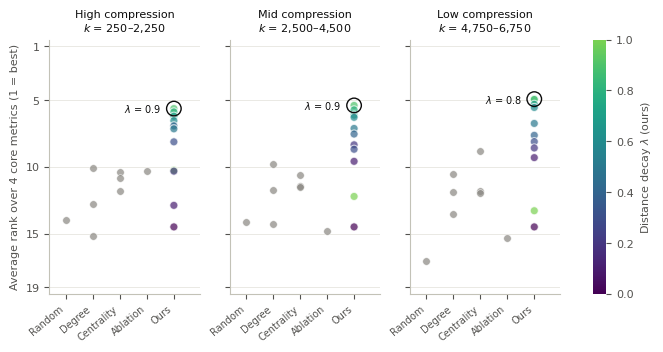

In [18]:
# Figure: average rank by method family and compression level (ours coloured by lambda)
FAMILIES = [("random", "Random"), ("degree-based", "Degree"), ("centrality-based", "Centrality"),
            ("ours(ablation)", "Ablation"), ("ours", "Ours")]
BASE_COLOR = "#898781"
lam_cmap = LinearSegmentedColormap.from_list("lam_viridis", plt.cm.viridis(np.linspace(0.0, 0.8, 256)))
n_methods = len(RANKED_METHODS)

fig, axes = plt.subplots(1, 3, figsize=(7.2, 3.3), sharey=True)
x_pos = {fam: i for i, (fam, _) in enumerate(FAMILIES)}
for ax, (lvl, (lo, hi)) in zip(axes, LEVELS.items()):
    d = rank_table.filter(pl.col("level") == lvl)
    for fam, _ in FAMILIES[:-1]:
        sub = d.filter(pl.col("family") == fam)
        ax.scatter(np.full(sub.height, x_pos[fam]), sub["avg_rank"], s=30, color=BASE_COLOR,
                   edgecolor="white", linewidth=0.5, zorder=3, alpha=0.7)
    ours = d.filter(pl.col("family") == "ours").with_columns(pl.col("method").cast(pl.Float64).alias("lam"))
    ax.scatter(np.full(ours.height, x_pos["ours"]), ours["avg_rank"], s=34, c=ours["lam"], cmap=lam_cmap,
               vmin=0, vmax=1, edgecolor="white", linewidth=0.8, zorder=4, alpha=0.7)
    best = ours.sort("avg_rank").row(0, named=True)
    ax.scatter([x_pos["ours"]], [best["avg_rank"]], s=110, facecolor="none", edgecolor=INK, linewidth=1.0, zorder=5)
    ax.annotate(f"$\\lambda$ = {best['lam']:.1f}", (x_pos["ours"], best["avg_rank"]), xytext=(-9, 0),
                textcoords="offset points", ha="right", va="center", fontsize=7, color=INK)
    ax.set_title(f"{lvl.capitalize()} compression\n$k$ = {lo:,}–{hi:,}", fontsize=8, color=INK)
    ax.set_xticks(range(len(FAMILIES)))
    ax.set_xticklabels([lab for _, lab in FAMILIES], rotation=40, ha="right", fontsize=7)
    ax.set_xlim(-0.6, len(FAMILIES) - 0.05)
    ax.grid(axis="y", color=GRID, lw=0.5)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylim(n_methods + 0.5, 0.5)
axes[0].set_yticks([1, 5, 10, 15, n_methods])
axes[0].set_ylabel(f"Average rank over {len(CORE)} core metrics (1 = best)")
sm = plt.cm.ScalarMappable(cmap=lam_cmap, norm=plt.Normalize(0, 1))
cbar = fig.colorbar(sm, ax=axes, fraction=0.025, pad=0.06)
cbar.set_label("Distance decay $\\lambda$ (ours)", color=INK2)
cbar.outline.set_visible(False)
save_fig(fig, "rank_by_family")

## 8. Effect of the token budget $k$  → Sec. 4.2, Figure "metrics vs k"

Main text: the 4 core metrics. Appendix: the same figure with random selection and the uncovered branch rate.

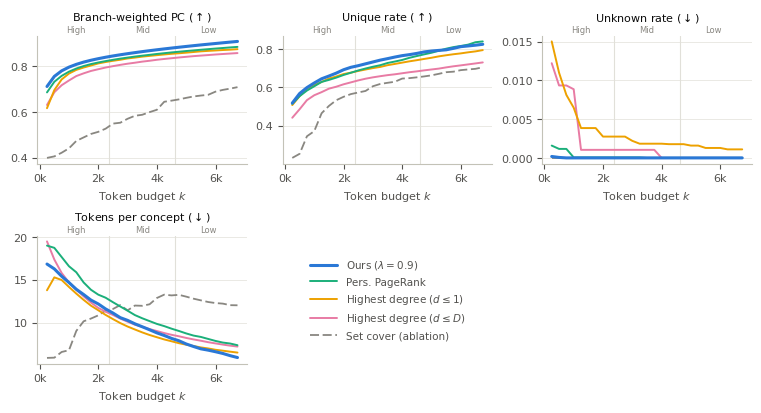

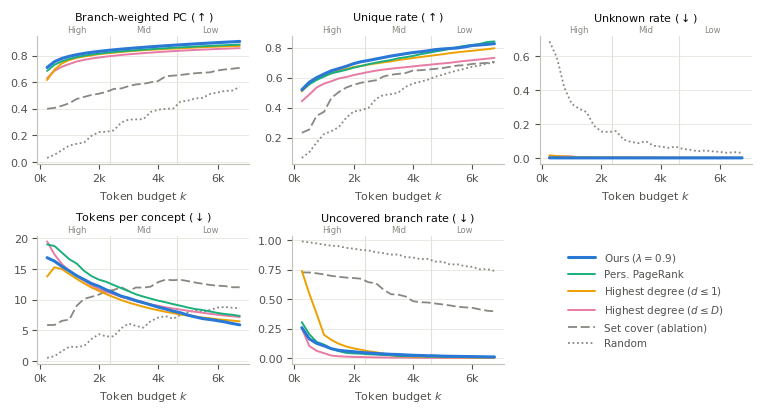

In [19]:
SERIES = {
    LAM_MAIN:                ("Ours ($\\lambda{=}" + LAM_MAIN + "$)", "#2a78d6", 2.2, "-"),
    "personalized_pagerank": ("Pers. PageRank",                    "#1baf7a", 1.4, "-"),
    "highest_degree_dist_1": ("Highest degree ($d \\leq 1$)",      "#eda100", 1.4, "-"),
    "highest_degree":        ("Highest degree ($d \\leq D$)",      "#e87ba4", 1.4, "-"),
    ABLATION:                ("Set cover (ablation)",              "#898781", 1.3, (0, (5, 2))),
    "k_random_all_samples":  ("Random",                            "#898781", 1.3, (0, (1, 1.5))),
}
LEVEL_EDGES = [(LEVELS["high"][1] + LEVELS["mid"][0]) / 2, (LEVELS["mid"][1] + LEVELS["low"][0]) / 2]
LEVEL_LABELS = [((lo + hi) / 2, lvl.capitalize()) for lvl, (lo, hi) in LEVELS.items()]


def plot_metrics_vs_k(df_k, metrics, series, ncols=3, panel_size=(2.5, 2)):
    n_panels = len(metrics) + 1                                   # +1 slot for the legend
    nrows = -(-n_panels // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_size[0] * ncols, panel_size[1] * nrows),
                             sharex=True, constrained_layout=True)
    axes = np.atleast_1d(axes).flatten()
    for ax, metric in zip(axes, metrics):
        for x in LEVEL_EDGES:
            ax.axvline(x, color=GRID, lw=0.8, zorder=0)
        for meth, (lab, color, lw, ls) in reversed(list(series.items())):
            sub = df_k.filter(pl.col("method") == meth).sort("k")
            if sub.height:
                ax.plot(sub["k"], sub[metric], color=color, lw=lw, ls=ls, label=lab,
                        zorder=3 if meth == LAM_MAIN else 2, solid_capstyle="round")
        ax.set_title(METRIC_TITLE.get(metric, metric), fontsize=8, color=INK, pad=11)
        ax.grid(axis="y", color=GRID, lw=0.5)
        ax.set_axisbelow(True)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        for x, lab in LEVEL_LABELS:
            ax.text(x, 1.01, lab, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=6, color=MUTED)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:g}k"))
        ax.tick_params(labelbottom=True)
        ax.set_xlabel("Token budget $k$", color=INK2)
    for ax in axes[len(metrics):]:
        ax.axis("off")
    handles, labels = axes[0].get_legend_handles_labels()
    order = [labels.index(series[m][0]) for m in series if series[m][0] in labels]
    axes[len(metrics)].legend([handles[i] for i in order], [labels[i] for i in order], loc="center",
                              frameon=False, fontsize=7.5, labelcolor=INK2, handlelength=2.6)
    return fig


main_series = {m: s for m, s in SERIES.items() if m != "k_random_all_samples"}
save_fig(plot_metrics_vs_k(perf, CORE, main_series), "metrics_vs_k")
save_fig(plot_metrics_vs_k(perf, CORE + ["uncovered_branch_rate"], SERIES), "metrics_vs_k_appendix")

In [20]:
# budgets at which each method first reaches a milestone (quotable in the text)
milestones = (perf.filter(pl.col("method").is_in(RANKED_METHODS))
                  .group_by(["method", "display"])
                  .agg(pl.col("k").filter(pl.col("unknown_rate") == 0).min().alias("min_k_unknown_0"),
                       pl.col("k").filter(pl.col("unique_rate") >= 0.9).min().alias("min_k_unique_90"),
                       pl.col("br_weighted_PC").max().alias("max_br_weighted_PC"))
                  .sort("min_k_unknown_0", nulls_last=True))
save_table(milestones, "milestones_vs_k")
milestones

method,display,min_k_unknown_0,min_k_unique_90,max_br_weighted_PC
str,str,i64,i64,f64
"""1.0""","""Ours ($\lambda$ = 1.0)""",250,null,0.818613
"""discrete_set_cover""","""Set cover (ablation)""",250,null,0.707655
"""0.9""","""Ours ($\lambda$ = 0.9)""",750,null,0.906806
"""0.8""","""Ours ($\lambda$ = 0.8)""",1250,null,0.907267
"""0.7""","""Ours ($\lambda$ = 0.7)""",1500,null,0.907157
…,…,…,…,…
"""highest_degree""","""Highest degree ($d \leq D$)""",4000,null,0.856031
"""closeness_centrality""","""Closeness centrality""",5750,null,0.861571
"""k_random_all_samples""","""Random""",null,null,0.564187


### 8b. Effectively used tokens (informational)

`num_effective_token` counts the selected tokens that at least one concept of $M$ uses. A token is unused when every concept that could reach it stops earlier at another token. Not ranked.
* `share_*`: mean of `num_effective_token / k` over the budgets of each level.
* `used_k*`: `num_effective_token` at $k$ = `k_main`.

In [21]:
eff_share = (perf.filter(pl.col("method").is_in(RANKED_METHODS))
                 .with_columns(level_expr().alias("level"))
                 .filter(pl.col("level").is_not_null())
                 .group_by(["method", "display", "family", "level"])
                 .agg(pl.col("effective_token_share").mean())
                 .pivot(on="level", index=["method", "display", "family"], values="effective_token_share")
                 .rename({lvl: f"share_{lvl}" for lvl in LEVELS})
                 .select("method", "display", "family", *[f"share_{lvl}" for lvl in LEVELS]))
eff_k = (perf.filter(pl.col("method").is_in(RANKED_METHODS) & (pl.col("k") == CFG.k_main))
             .select("method", pl.col("num_effective_token").round(0).cast(pl.Int64).alias(f"used_k{CFG.k_main}")))
eff = eff_share.join(eff_k, on="method", how="left").sort("share_high", descending=True)
save_table(eff, "effective_tokens")
with pl.Config(tbl_rows=30, tbl_cols=12, fmt_str_lengths=40):
    display(eff.drop("method"))

display,family,share_high,share_mid,share_low,used_k5000
str,str,f64,f64,f64,i64
"""Ours ($\lambda$ = 0.5)""","""ours""",1.0,1.0,1.0,5000
"""Ours ($\lambda$ = 0.6)""","""ours""",1.0,1.0,0.999914,5000
"""Highest degree ($d \leq 1$)""","""degree-based""",1.0,1.0,0.997508,4997
"""Ours ($\lambda$ = 0.1)""","""ours""",1.0,1.0,1.0,5000
"""Ours ($\lambda$ = 0.4)""","""ours""",1.0,1.0,1.0,5000
"""Ours ($\lambda$ = 0.3)""","""ours""",1.0,1.0,1.0,5000
"""Ours ($\lambda$ = 0.2)""","""ours""",1.0,1.0,1.0,5000
"""Ours ($\lambda$ = 0.0)""","""ours""",1.0,1.0,1.0,5000
"""Ours ($\lambda$ = 0.7)""","""ours""",0.999508,0.999408,0.999374,4998


## 9. Effect of the distance decay $\lambda$  → Sec. 4.2, Figure/Table "effect of lambda"

Our method only. Each value is the mean over the budgets of a compression level.
* The figure leaves out $\lambda$ = 0. The table keeps it.
* The fine grid 0.91–0.99 shows the drop at exactly $\lambda$ = 1.

% --- high compression
0.0 & 0.088 & 0.121 & 0.736 & 0.334 & 0.923 \\
0.1 & 0.603 & 0.522 & 0.016 & 6.619 & 0.799 \\
0.2 & 0.712 & 0.608 & 0.003 & 11.153 & 0.576 \\
0.3 & 0.757 & 0.631 & 0.001 & 12.568 & 0.415 \\
0.4 & 0.777 & 0.644 & 0.001 & 13.649 & 0.325 \\
0.5 & 0.786 & 0.642 & 0.001 & 14.169 & 0.225 \\
0.6 & 0.790 & 0.644 & 0.001 & 14.174 & 0.199 \\
0.7 & 0.793 & 0.639 & 0.000 & 14.111 & 0.144 \\
0.8 & 0.795 & 0.635 & 0.000 & 14.098 & 0.125 \\
0.9 & 0.795 & 0.632 & 0.000 & 14.089 & 0.105 \\
1.0 & 0.717 & 0.520 & 0.000 & 13.844 & 0.020 \\
% --- mid compression
0.0 & 0.247 & 0.337 & 0.369 & 0.950 & 0.784 \\
0.1 & 0.714 & 0.682 & 0.000 & 5.903 & 0.660 \\
0.2 & 0.795 & 0.726 & 0.000 & 9.083 & 0.449 \\
0.3 & 0.831 & 0.747 & 0.000 & 9.859 & 0.298 \\
0.4 & 0.846 & 0.758 & 0.000 & 10.336 & 0.208 \\
0.5 & 0.854 & 0.757 & 0.000 & 10.257 & 0.120 \\
0.6 & 0.858 & 0.759 & 0.000 & 9.970 & 0.085 \\
0.7 & 0.860 & 0.754 & 0.000 & 9.827 & 0.050 \\
0.8 & 0.861 & 0.751 & 0.000 & 9.690 & 0.038 \\
0.9 

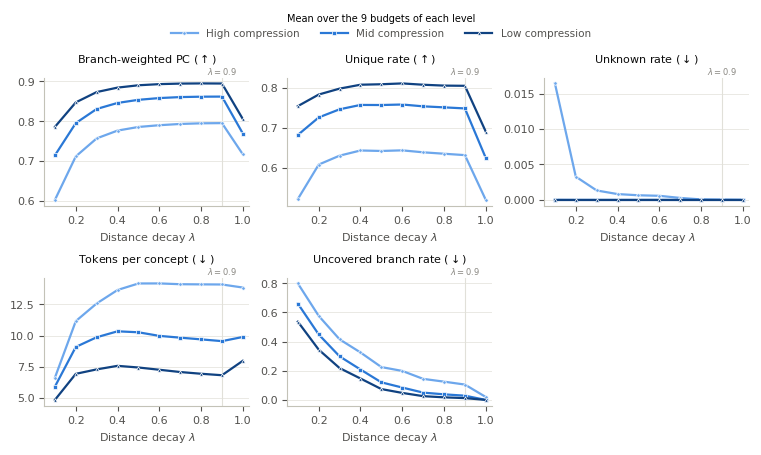

In [22]:
LEVEL_STYLE = {"high": ("#6da7ec", "o"), "mid": ("#2a78d6", "s"), "low": ("#104281", "^")}
METRICS_LAMBDA = CORE + ["uncovered_branch_rate"]

df_lam = (perf.filter(pl.col("family") == "ours")
              .with_columns(pl.col("method").cast(pl.Float64).alias("lam"), level_expr().alias("level"))
              .filter(pl.col("level").is_not_null())
              .group_by(["level", "lam"]).agg([pl.col(m).mean() for m in METRICS_ALL])
              .sort(["level", "lam"]))
save_table(df_lam, "effect_of_lambda")


def plot_metrics_vs_lambda(df_lam, metrics, ncols=3, panel_size=(2.5, 2)):
    nrows = -(-len(metrics) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_size[0] * ncols, panel_size[1] * nrows),
                             sharex=True, constrained_layout=True)
    axes = np.atleast_1d(axes).flatten()
    for ax, metric in zip(axes, metrics):
        ax.axvline(CFG.lam_main, color=GRID, lw=0.8, zorder=0)
        ax.text(CFG.lam_main, 1.01, f"$\\lambda{{=}}{LAM_MAIN}$", transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=6, color=MUTED)
        for lvl, (color, mk) in LEVEL_STYLE.items():
            sub = df_lam.filter((pl.col("level") == lvl) & (pl.col("lam") > 0)).sort("lam")
            ax.plot(sub["lam"], sub[metric], color=color, lw=1.6, marker=mk, markersize=2.5,
                    markeredgecolor="white", markeredgewidth=0.5, label=f"{lvl.capitalize()} compression")
        ax.set_title(METRIC_TITLE.get(metric, metric), fontsize=8, color=INK, pad=11)
        ax.grid(axis="y", color=GRID, lw=0.5)
        ax.set_axisbelow(True)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        ax.xaxis.set_major_locator(MultipleLocator(0.2))
        ax.set_xlim(0.05, 1.03)
        ax.tick_params(labelbottom=True)
        ax.set_xlabel("Distance decay $\\lambda$", color=INK2)
    for ax in axes[len(metrics):]:
        ax.axis("off")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), bbox_transform=fig.transFigure,
               ncol=3, frameon=False, fontsize=7.5, labelcolor=INK2,
               title=f"Mean over the {n_lvl} budgets of each level", title_fontsize=7, handlelength=2.6)
    return fig


save_fig(plot_metrics_vs_lambda(df_lam, METRICS_LAMBDA), "metrics_vs_lambda")

# LaTeX rows: coarse lambdas incl. 0, one block per level
for lvl in LEVELS:
    print(f"% --- {lvl} compression")
    for r in df_lam.filter((pl.col("level") == lvl) & pl.col("lam").is_in([float(l) for l in LAMBDA_IDS])).iter_rows(named=True):
        print(f"{r['lam']:.1f} & " + " & ".join(f"{r[m]:.3f}" for m in METRICS_LAMBDA) + r" \\")

## 10. Distribution of the branch-weighted PC  → Sec. 3.6 (metric), 5.3 (discussion)

The mean hides how the branch-weighted PC is distributed over concepts. At $k$ = `k_main`, this section shows:
* the per-concept ECDF for our method and the main baselines;
* branch-weighted completeness vs proximity for our method, i.e. *where* the loss comes from: branches without a token, or distant tokens ($\text{br\_weighted\_PC} = \text{br\_completeness} \times \text{br\_proximity}$).

In [23]:
DIST_METHODS = [LAM_MAIN, "1.0", "personalized_pagerank", "highest_degree_dist_1", ABLATION]
pc_by_method = {}
for meth in DIST_METHODS:
    if meth == LAM_MAIN:
        pc_by_method[meth] = pc_main
    else:
        _, pc = fe.evaluate_token_set(M, adj, ranked_tokens(meth)[:CFG.k_main], D, return_per_concept=True)
        pc_by_method[meth] = pc

SCORE = "br_weighted_PC"
dist_summary = pl.DataFrame([
    {"method": DISPLAY[m], **{q: float(pc[SCORE].quantile(p, "nearest"))
                              for q, p in [("p10", .10), ("p25", .25), ("median", .5), ("p75", .75)]},
     "mean": float(pc[SCORE].mean()),
     "share_ge_0.5": float((pc[SCORE] >= 0.5).mean()),
     "share_exact (=1)": float((pc[SCORE] == 1).mean())}
    for m, pc in pc_by_method.items()])
save_table(dist_summary, f"br_pc_distribution_k{CFG.k_main}")
dist_summary

method,p10,p25,median,p75,mean,share_ge_0.5,share_exact (=1)
str,f64,f64,f64,f64,f64,f64,f64
"""Ours ($\lambda$ = 0.9)""",0.8125,0.841039,0.868889,0.9,0.884918,1.0,0.195907
"""Ours ($\lambda$ = 1.0)""",0.625,0.701042,0.775,0.9,0.793622,0.985461,0.23934
"""Personalized PageRank""",0.795238,0.830417,0.866667,0.9,0.864932,0.999695,0.104154
"""Highest degree ($d \leq 1$)""",0.793827,0.833333,0.866667,0.9,0.85786,0.996701,0.060354
"""Set cover (ablation)""",0.49146,0.575,0.660628,0.74808,0.661033,0.89157,0.032865


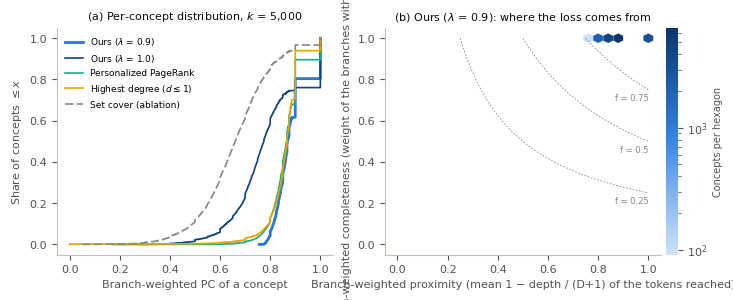

In [24]:
COLORS = {LAM_MAIN: "#2a78d6", "1.0": "#104281", "personalized_pagerank": "#1baf7a",
          "highest_degree_dist_1": "#eda100", ABLATION: "#898781"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 2.9), constrained_layout=True)
for m, pc in pc_by_method.items():
    x = np.sort(pc[SCORE].to_numpy())
    ax1.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=COLORS[m],
             lw=2.0 if m == LAM_MAIN else 1.2, ls=(0, (5, 2)) if m == ABLATION else "-", label=DISPLAY[m])
ax1.set_xlabel(f"{FIDELITY_NAME} of a concept", color=INK2)
ax1.set_ylabel("Share of concepts $\\leq x$", color=INK2)
ax1.legend(frameon=False, fontsize=6.5, loc="upper left")
ax1.set_title(f"(a) Per-concept distribution, $k$ = {CFG.k_main:,}", fontsize=8, color=INK)

rep = pc_main.filter(~pl.col("unknown"))
hb = ax2.hexbin(rep["br_proximity"], rep["br_completeness"], gridsize=25, bins="log", cmap=ep.SEQ_BLUE,
                mincnt=1, linewidths=0.15, edgecolors="white", extent=(0, 1, 0, 1))
for f_iso in (0.25, 0.5, 0.75):                         # iso-PC curves: completeness = PC / proximity
    xx = np.linspace(f_iso, 1, 100)
    ax2.plot(xx, f_iso / xx, color=MUTED, lw=0.6, ls=(0, (2, 2)))
    ax2.text(1.0, f_iso - 0.02, f"f = {f_iso}", fontsize=6, color=MUTED, ha="right", va="top")
ax2.set_xlabel("Branch-weighted proximity (mean 1 − depth / (D+1) of the tokens reached)", color=INK2)
ax2.set_ylabel("Branch-weighted completeness (weight of the branches with a token)", color=INK2)
ax2.set_title(f"(b) Ours ($\\lambda$ = {LAM_MAIN}): where the loss comes from", fontsize=8, color=INK)
cb = fig.colorbar(hb, ax=ax2, fraction=0.05, pad=0.02)
cb.set_label("Concepts per hexagon", color=INK2, fontsize=7)
cb.outline.set_visible(False)
for ax in (ax1, ax2):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
save_fig(fig, "br_pc_distribution")

## 11. Patient data: our tokenizer vs frequency truncation  → Sec. 4.3

Our tokenizer at $\lambda$ = `lam_main`, $k$ from 250 to $|M|$. Truncation keeps the $k$ most frequent concepts and maps every other concept to one shared UNK token.

**New compared with notebook 6:** per-code branch-weighted PC.
* Truncation has a branch-weighted PC of **1** for a kept concept (it is its own token) and **0** for UNK.
* The table by frequency shows how much meaning rare concepts keep.

In [25]:
Ks_ehr = sorted({k for k in CFG.ks_ehr if k < len(M)} | {len(M)})
path_pc = DIRS["ehr"] + f"per_code_{LAM_MAIN}.parquet"


def fidelity_per_code(ranked, Ks):
    frames = []
    for K in Ks:
        trees = build_context_trees(M, adj, set(ranked[:K]), D)
        frames.append(fe.per_concept_table(trees, D)
                        .select(pl.col("concept").alias("code"), "fidelity", "completeness", "proximity")
                        .with_columns(pl.lit(K).alias("k")))
    return pl.concat(frames)


BR_COLS = ["br_weighted_PC", "br_completeness", "br_proximity"]


def br_per_code(ranked, Ks):
    # branch-weighted PC of every code of M at every k (no context tree needed)
    frames = []
    for K in Ks:
        br = br_weighted_pc_per_concept(M, adj, set(ranked[:K]), D)
        frames.append(pl.DataFrame({"code": M, **{c: br[c] for c in BR_COLS}}).with_columns(pl.lit(K, dtype=pl.Int64).alias("k")))
    return pl.concat(frames)


def with_br(pc, ranked):
    # add the branch-weighted columns to a per_code table, also to one cached before they existed;
    # truncation: a kept code is its own token (br_weighted_PC = 1), UNK gets 0
    pc = pc.drop([c for c in BR_COLS + ["trunc_br_weighted_PC"] if c in pc.columns]).with_columns(pl.col("k").cast(pl.Int64))
    return (pc.join(br_per_code(ranked, sorted(pc["k"].unique().to_list())), on=["k", "code"], how="left")
              .with_columns(pl.col("trunc_kept").cast(pl.Float64).alias("trunc_br_weighted_PC")))


def per_code_for(ranked, Ks):
    pc = et.tokenize_all_k(M, ranked, Ks, adj, D, df_freq, id_to_label)
    pc = pc.join(fidelity_per_code(ranked, Ks), on=["k", "code"], how="left")
    pc = pc.with_columns(pl.col("occurrences").cast(pl.Int64),
                         pl.col("trunc_kept").cast(pl.Float64).alias("trunc_fidelity"))   # legacy PC of truncation
    return with_br(pc, ranked)


if CFG.recompute or not os.path.exists(path_pc):
    assert len(ranked_main) >= len(M), "the main lambda run must contain |M| tokens (Section 3)"
    per_code_for(ranked_main, Ks_ehr).write_parquet(path_pc)
per_code = pl.read_parquet(path_pc)
if not set(BR_COLS) <= set(per_code.columns):          # cached before br_weighted_PC existed: add it (fast)
    per_code = with_br(per_code, ranked_main)
    per_code.write_parquet(path_pc)

cov, cst, uniq = et.coverage(per_code), et.cost(per_code), et.uniqueness(per_code)
toks, lt = et.token_stats(per_code), et.longtail(per_code)
for name, t in [("coverage", cov), ("cost", cst), ("uniqueness", uniq), ("token_stats", toks), ("longtail", lt)]:
    t.write_csv(DIRS["ehr"] + f"{name}.csv")
cov

k,ours_pct_codes,ours_pct_events,trunc_pct_codes,trunc_pct_events,ours_pct_codes_partly_unknown
i64,f64,f64,f64,f64,f64
250,99.981674,99.998146,1.527184,82.237701,25.791081
500,99.993891,99.998152,3.054368,92.538921,16.23091
1000,100.0,100.0,6.108735,97.526148,10.268784
2000,100.0,100.0,12.217471,99.285353,5.302382
3500,100.0,100.0,21.380574,99.758432,2.871106
5000,100.0,100.0,30.543677,99.896001,1.49664
7500,100.0,100.0,45.815516,99.969607,0.708613
10000,100.0,100.0,61.087355,99.99028,0.256567
16370,100.0,100.0,100.0,100.0,0.0


% tab:ehr  (k | concepts ours, trunc | events ours, trunc | uncovered | unique tree, flat, tree-events | rare >= 10 | tokens/event)
250 & $>$99.9 & 1.5 & $>$99.9 & 82.2 & 25.8 & 51.8 & 41.9 & 21.4 & 100.0 & 9.3 \\
500 & $>$99.9 & 3.1 & $>$99.9 & 92.5 & 16.2 & 56.8 & 50.5 & 29.8 & 100.0 & 8.6 \\
1,000 & 100.0 & 6.1 & 100.0 & 97.5 & 10.3 & 62.3 & 58.7 & 41.2 & 100.0 & 7.6 \\
2,000 & 100.0 & 12.2 & 100.0 & 99.3 & 5.3 & 69.3 & 67.1 & 55.1 & 99.8 & 6.9 \\
3,500 & 100.0 & 21.4 & 100.0 & 99.8 & 2.9 & 75.1 & 73.9 & 65.3 & 97.9 & 6.0 \\
5,000 & 100.0 & 30.5 & 100.0 & 99.9 & 1.5 & 79.1 & 78.2 & 68.0 & 94.1 & 5.6 \\
7,500 & 100.0 & 45.8 & 100.0 & $>$99.9 & 0.7 & 83.9 & 83.5 & 73.3 & 85.7 & 5.2 \\
10,000 & 100.0 & 61.1 & 100.0 & $>$99.9 & 0.3 & 88.5 & 88.1 & 77.8 & 76.1 & 4.8 \\
16,370 & 100.0 & 100.0 & 100.0 & 100.0 & 0.0 & 97.3 & 97.3 & 98.5 & 51.7 & 1.8 \\

% tab:longtail at k = 5000
$< 10$ & 5,706 & $<$0.1 & 0.0 & 84.3 & 535 & 185.1 & 89.0 & 9.0 \\
$[10, 100)$ & 4,903 & 0.1 & 0.0 & 80.0 & 763 

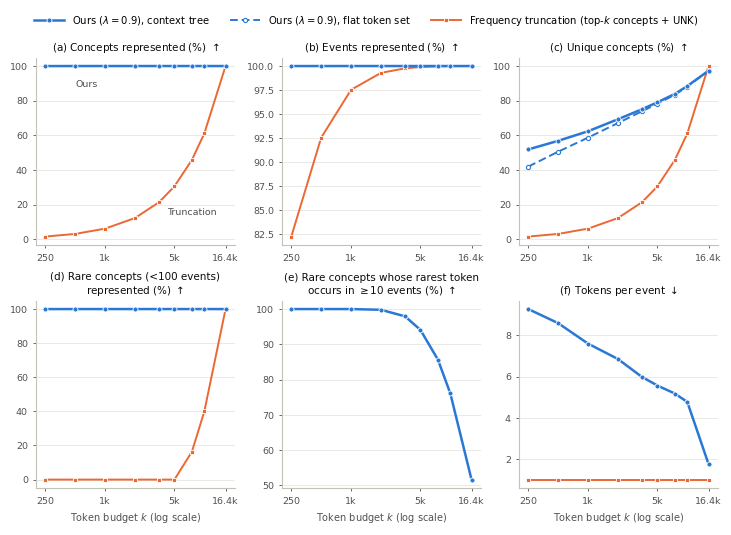

In [26]:
# Figure: coverage, uniqueness, rare concepts and sequence cost vs k (notebook 6 figure)
fig = ep.plot_ehr_summary(cov, cst, uniq, lt, rare=CFG.rare_token_events)
save_fig(fig, "ehr_summary")

print("% tab:ehr  (k | concepts ours, trunc | events ours, trunc | uncovered | unique tree, flat, tree-events | rare >= 10 | tokens/event)")
print(ept.ehr_rows(per_code))
print(f"\n% tab:longtail at k = {CFG.k_main}")
print(ept.longtail_rows(per_code, k=CFG.k_main))

8.0% of represented concepts gain nothing (rarest token as rare as the concept)


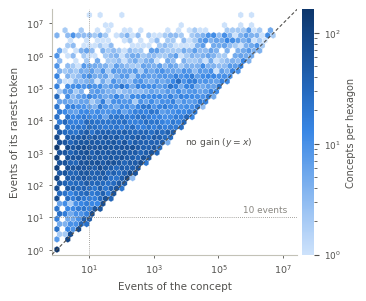

In [27]:
# Borrowed strength: events of each concept vs events of its rarest token
fig, on_diag = ep.plot_borrowed_strength(per_code, k=CFG.k_main, rare=CFG.rare_token_events)
save_fig(fig, f"borrowed_strength_k{CFG.k_main}")
print(f"{on_diag:.1%} of represented concepts gain nothing (rarest token as rare as the concept)")

### 11b. Branch-weighted PC on patient data

* **By $k$:** mean branch-weighted PC over concepts, and weighted by events (ours vs truncation).
* **By frequency bin at $k$ = `k_main`:** ours, truncation, and ours restricted to the concepts truncation drops. Optional: the extra baselines from `CFG.ehr_extra_baselines`.

In [28]:
SCORE, TRUNC_SCORE = "br_weighted_PC", "trunc_br_weighted_PC"
occ_f = pl.col("occurrences").cast(pl.Float64)
score_by_k = (per_code.group_by("k").agg(
                  pl.col(SCORE).mean().alias("ours_br_pc_concepts"),
                  pl.col(TRUNC_SCORE).mean().alias("trunc_br_pc_concepts"),
                  ((pl.col(SCORE) * occ_f).sum() / occ_f.sum()).alias("ours_br_pc_events"),
                  ((pl.col(TRUNC_SCORE) * occ_f).sum() / occ_f.sum()).alias("trunc_br_pc_events"),
                  pl.col(SCORE).filter(pl.col("trunc_kept") == False).mean().alias("ours_br_pc_on_trunc_dropped"),
              ).sort("k"))
save_table(score_by_k, "ehr_br_pc_by_k")

BINS = [(0, 10, "$< 10$"), (10, 100, "$[10, 100)$"), (100, 1000, "$[100, 1000)$"), (1000, None, "$\\ge 1000$")]


def score_by_bin(pc, k, prefix="ours"):
    d = pc.filter(pl.col("k") == k)
    rows = []
    for lo, hi, lab in BINS:
        m = pl.col("occurrences") >= lo
        if hi is not None:
            m = m & (pl.col("occurrences") < hi)
        b = d.filter(m)
        dropped = b.filter(pl.col("trunc_kept") == False)
        rows.append({"bin": lab, "n_concepts": b.height,
                     f"{prefix}_mean": float(b[SCORE].mean()) if b.height else None,
                     f"{prefix}_median": float(b[SCORE].median()) if b.height else None,
                     f"{prefix}_on_trunc_dropped": float(dropped[SCORE].mean()) if dropped.height else None,
                     "trunc_mean": float(b[TRUNC_SCORE].mean()) if b.height else None})
    return pl.DataFrame(rows)


score_bin = score_by_bin(per_code, CFG.k_main)
for b in CFG.ehr_extra_baselines:
    path_b = DIRS["ehr"] + f"per_code_{b}.parquet"
    if CFG.recompute or not os.path.exists(path_b):
        per_code_for(ranked_tokens(b), [CFG.k_main]).write_parquet(path_b)
    pc_b = pl.read_parquet(path_b)
    if not set(BR_COLS) <= set(pc_b.columns):           # cached before br_weighted_PC existed
        pc_b = with_br(pc_b, ranked_tokens(b))
        pc_b.write_parquet(path_b)
    fb = score_by_bin(pc_b, CFG.k_main, prefix=b)
    score_bin = score_bin.join(fb.select("bin", f"{b}_mean", f"{b}_on_trunc_dropped"), on="bin", how="left")
save_table(score_bin, f"ehr_br_pc_by_bin_k{CFG.k_main}")

print(f"% tab:longtail-br-pc at k = {CFG.k_main}: bin | concepts | ours mean | ours median | trunc mean | ours on trunc-dropped")
for r in score_bin.iter_rows(named=True):
    print(" & ".join([r["bin"], f"{r['n_concepts']:,}", fmt(r["ours_mean"], 2), fmt(r["ours_median"], 2),
                      fmt(r["trunc_mean"], 2), fmt(r["ours_on_trunc_dropped"], 2)]) + r" \\")
score_bin

% tab:longtail-br-pc at k = 5000: bin | concepts | ours mean | ours median | trunc mean | ours on trunc-dropped
$< 10$ & 5,706 & 0.88 & 0.86 & 0.00 & 0.88 \\
$[10, 100)$ & 4,903 & 0.88 & 0.87 & 0.00 & 0.88 \\
$[100, 1000)$ & 3,246 & 0.89 & 0.88 & 0.77 & 0.89 \\
$\ge 1000$ & 2,515 & 0.90 & 0.90 & 1.00 & n/a \\


bin,n_concepts,ours_mean,ours_median,ours_on_trunc_dropped,trunc_mean,personalized_pagerank_mean,personalized_pagerank_on_trunc_dropped
str,i64,f64,f64,f64,f64,f64,f64
"""$< 10$""",5706,0.875848,0.863889,0.875848,0.0,0.854414,0.854414
"""$[10, 100)$""",4903,0.884384,0.866667,0.884384,0.0,0.863583,0.863583
"""$[100, 1000)$""",3246,0.893311,0.875,0.888294,0.765558,0.874112,0.871928
"""$\ge 1000$""",2515,0.895706,0.9,null,1.0,0.879575,null


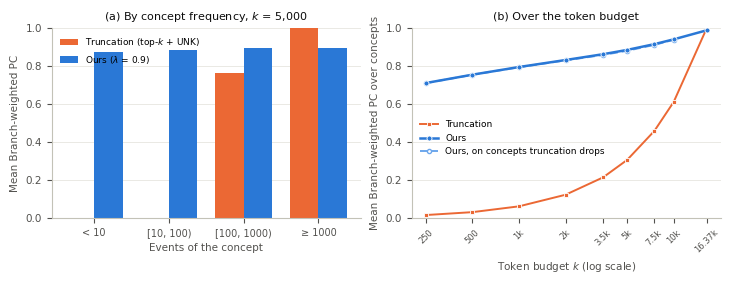

In [29]:
# Figure: branch-weighted PC by frequency bin (ours vs truncation) and over k
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 2.7), constrained_layout=True)
x = np.arange(len(score_bin))
w = 0.38
ax1.bar(x - w / 2, score_bin["trunc_mean"], w, color=ep.TRUNC, label="Truncation (top-$k$ + UNK)")
ax1.bar(x + w / 2, score_bin["ours_mean"], w, color=ep.OURS, label=f"Ours ($\\lambda$ = {LAM_MAIN})")
ax1.set_xticks(x)
ax1.set_xticklabels([b.replace("$", "").replace("\\ge ", "≥ ") for b in score_bin["bin"]], fontsize=7)
ax1.set_xlabel("Events of the concept", color=INK2)
ax1.set_ylabel(f"Mean {FIDELITY_NAME}", color=INK2)
ax1.set_ylim(0, 1)
ax1.set_title(f"(a) By concept frequency, $k$ = {CFG.k_main:,}", fontsize=8, color=INK)
ax1.legend(frameon=False, fontsize=6.5, loc="upper left")

t = score_by_k.sort("k")
ax2.plot(t["k"], t["trunc_br_pc_concepts"], **ep.STYLE["truncation"], label="Truncation")
ax2.plot(t["k"], t["ours_br_pc_concepts"], **ep.STYLE["ours"], label="Ours")
ax2.plot(t["k"], t["ours_br_pc_on_trunc_dropped"], color="#6da7ec", lw=1.4, ls=(0, (4, 2)), marker="o",
         ms=3.0, mfc="white", label="Ours, on concepts truncation drops")
ax2.set_xscale("log")
ax2.xaxis.set_major_locator(plt.FixedLocator(Ks_ehr))
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:g}k" if v >= 1000 else f"{v:g}"))
ax2.xaxis.set_minor_locator(plt.NullLocator())
ax2.tick_params(axis="x", labelsize=6, rotation=45)
ax2.set_xlabel("Token budget $k$ (log scale)", color=INK2)
ax2.set_ylabel(f"Mean {FIDELITY_NAME} over concepts", color=INK2)
ax2.set_ylim(0, 1)
ax2.set_title("(b) Over the token budget", fontsize=8, color=INK)
ax2.legend(frameon=False, fontsize=6.5, loc="center left", bbox_to_anchor=(0.0, 0.42))
for ax in (ax1, ax2):
    ax.grid(axis="y", color=GRID, lw=0.5)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
save_fig(fig, "ehr_br_pc")

In [30]:
# Skew of the token-frequency distribution under four vocabularies (notebook 6, for the discussion)
dist = et.distribution_stats(per_code)
dist.write_csv(DIRS["ehr"] + "distribution_stats.csv")
dist.filter(pl.col("k") == CFG.k_main)

k,vocabulary,pct_events_kept,vocab_size,token_occurrences,max_token_share,median_token_occ,gini,entropy_norm,effective_vocab,zipf_slope,pct_tokens_lt_10,pct_tokens_lt_100
i64,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
5000,"""raw_codes""",100.0,16370,2.79122793e8,0.017741,28.0,0.978731,0.610445,373.63388,-2.944555,34.856445,64.807575
5000,"""trunc_unk""",100.0,5001,2.79122793e8,0.017741,1017.0,0.933132,0.694382,370.303114,-2.194422,0.0,0.0
5000,"""trunc_drop""",99.896001,5000,2.78832508e8,0.01776,1016.5,0.933221,0.694159,369.550703,-2.193666,0.0,0.0
5000,"""ours""",100.0,5000,9.6592269e8,0.143517,906.0,0.966617,0.566591,124.681375,-3.219809,11.44,27.12


## 12. Correlation between metrics, by method family  → Sec. 5.3

Spearman correlation over all (method, $k$) rows of a family. The question is whether the core metrics measure different things.

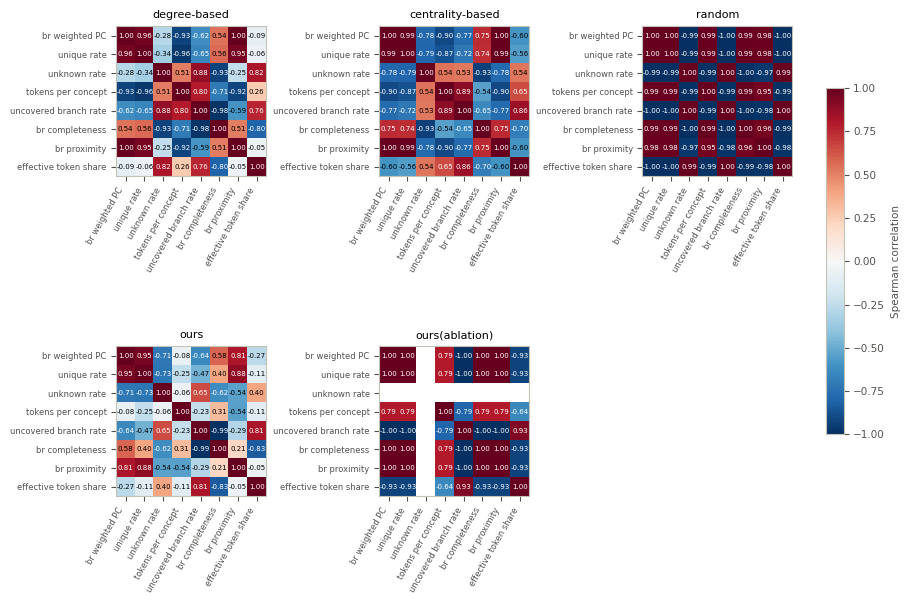

In [31]:
CORR_COLS = CORE + ["uncovered_branch_rate", "br_completeness", "br_proximity", "effective_token_share"]
fam_list = ["degree-based", "centrality-based", "random", "ours", "ours(ablation)"]
fig, axes = plt.subplots(2, 3, figsize=(9.0, 6.4), constrained_layout=True)
axes = axes.flatten()
axes[-1].axis("off")
corr_rows = []
for ax, fam in zip(axes, fam_list):
    sub = perf.filter(pl.col("family") == fam).select(CORR_COLS)
    ranks = np.column_stack([sub[c].rank("average").to_numpy() for c in CORR_COLS])
    with np.errstate(invalid="ignore", divide="ignore"):
        corr = np.corrcoef(ranks, rowvar=False)
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(CORR_COLS)))
    ax.set_yticks(range(len(CORR_COLS)))
    ax.set_xticklabels([c.replace("_", " ") for c in CORR_COLS], rotation=60, ha="right", fontsize=6)
    ax.set_yticklabels([c.replace("_", " ") for c in CORR_COLS], fontsize=6)
    ax.set_title(fam, fontsize=8)
    for i in range(len(CORR_COLS)):
        for j in range(len(CORR_COLS)):
            v = corr[i, j]
            ax.text(j, i, "" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=5,
                    color="white" if abs(np.nan_to_num(v)) > 0.6 else "black")
            corr_rows.append({"family": fam, "metric_1": CORR_COLS[i], "metric_2": CORR_COLS[j], "spearman": v})
fig.colorbar(im, ax=axes[:len(fam_list)], shrink=0.6, label="Spearman correlation")
save_fig(fig, "metric_correlations")
save_table(pl.DataFrame(corr_rows), "metric_correlations")

## 13. Key numbers for the text

The numbers the prose refers to, collected in one file (`tables/key_numbers.json`). Keep few numbers in the text and point to the tables and figures.

In [32]:
def row(df, **eq):
    d = df
    for k_, v in eq.items():
        d = d.filter(pl.col(k_) == v)
    return d.row(0, named=True) if d.height else None


r_main = row(perf, method=LAM_MAIN, k=CFG.k_main)
r_cov, r_uniq = row(cov, k=CFG.k_main), row(uniq, k=CFG.k_main)
r_cst, r_br = row(cst, k=CFG.k_main), row(score_by_k, k=CFG.k_main)
r_ppr = row(perf, method="personalized_pagerank", k=CFG.k_main)
rare = per_code.filter((pl.col("k") == CFG.k_main) & (pl.col("occurrences") < 100))

key = {
    "|M|": len(M),
    "k_main": CFG.k_main, "lam_main": CFG.lam_main,
    "compression k_main/|M| (%)": 100 * CFG.k_main / len(M),
    "benchmark @k_main, ours": {m: r_main[m] for m in METRICS_ALL} if r_main else None,
    "best method per level": {lvl: rank_table.filter(pl.col("level") == lvl).row(0, named=True)["display"]
                              for lvl in LEVELS},
    "ehr @k_main: concepts represented ours / trunc (%)": (r_cov["ours_pct_codes"], r_cov["trunc_pct_codes"]),
    "ehr @k_main: events represented ours / trunc (%)": (r_cov["ours_pct_events"], r_cov["trunc_pct_events"]),
    "ehr @k_main: unique tree / flat / trunc (%)": (r_uniq["ours_tree_pct_codes"], r_uniq["ours_flat_pct_codes"],
                                                    r_uniq["trunc_pct_codes"]),
    "ehr @k_main: tokens per event": r_cst["ours_tokens_per_event"],
    "benchmark @k_main: effective tokens ours / pers. PageRank": (r_main["num_effective_token"] if r_main else None,
                                                                  r_ppr["num_effective_token"] if r_ppr else None),
    "ehr @k_main: tokens used by the data (ours)": int(toks.filter(pl.col("k") == CFG.k_main)["n_used_tokens"][0]),
    "ehr @k_main: br_weighted_PC concepts ours / trunc": (r_br["ours_br_pc_concepts"], r_br["trunc_br_pc_concepts"]),
    "ehr @k_main: br_weighted_PC events ours / trunc": (r_br["ours_br_pc_events"], r_br["trunc_br_pc_events"]),
    "ehr @k_main: ours br_weighted_PC on concepts truncation drops": r_br["ours_br_pc_on_trunc_dropped"],
    "ehr @k_main: rare concepts (<100 events): n, represented ours / trunc (%)": (
        rare.height, 100 * float((~rare["unknown"]).mean()), 100 * float(rare["trunc_kept"].mean())),
    "ehr @k_main: rare concepts: mean br_weighted_PC ours / trunc": (float(rare["br_weighted_PC"].mean()),
                                                                     float(rare["trunc_br_weighted_PC"].mean())),
    "ehr @k_main: share of represented concepts with no borrowed strength": on_diag,
}
with open(os.path.join(DIRS["tables"], "key_numbers.json"), "w") as f:
    json.dump(key, f, indent=2, default=float)
print(json.dumps(key, indent=2, default=float))

{
  "|M|": 16370,
  "k_main": 5000,
  "lam_main": 0.9,
  "compression k_main/|M| (%)": 30.543677458766034,
  "benchmark @k_main, ours": {
    "br_weighted_PC": 0.8849183536277662,
    "br_completeness": 0.9999957884400756,
    "br_proximity": 0.8849217636423913,
    "br_weighted_PC_median": 0.868888888888889,
    "br_weighted_PC_p10": 0.8125000000000001,
    "br_weighted_PC_p25": 0.8410393205152433,
    "unique_rate": 0.7905314599877825,
    "unknown_rate": 0.0,
    "tokens_per_concept": 7.50122174709835,
    "uncovered_branch_rate": 0.014966401954795358,
    "semantic_fidelity": 0.8324045254640605,
    "completeness": 0.9993794282802267,
    "proximity": 0.8327279839988099,
    "fidelity_median": 0.85,
    "fidelity_p10": 0.6523809523809524,
    "fidelity_p25": 0.7571428571428571,
    "num_effective_token": 4991.0
  },
  "best method per level": {
    "high": "Ours ($\\lambda$ = 0.9)",
    "mid": "Ours ($\\lambda$ = 0.9)",
    "low": "Ours ($\\lambda$ = 0.8)"
  },
  "ehr @k_main: conc